## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

In [83]:
# read the dataset
data = pd.read_csv(r"datasets\amz_uk_price_prediction_dataset.csv") # read csv file

df = pd.DataFrame(data.copy())                                      # copying the file to have a raw file that stays like it is and a copy to work with

print(df.shape)                                                     # showing the shape of the dataset -> count of rows/columns

df.head()                                                           # showing first rows to validate that there is the correct data inside the file

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

**Conclusion Part 1:**
- 1. There are categories where being a best-seller is more prevalent, but not significant if you go for the percentage values (what makes more sense).
- 2. chi-square test: The p value (0.0) is smaller than 0.05. We do have a correlation between the two categorical variables "isBestSeller" and "category".
- 2. cramer's v: The result 0.12 is between the range of 0.1 and 0.2. That means that the strength of association is weak
- 3. I plotted the crosstab of the count_values as a bar chart but in the order of the normalized crosstab (percentage of). 

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [46]:

crosstab_df_value = pd.crosstab(df.category, df.isBestSeller)                       # display crosstab with value_count
crosstab_df_value_sorted = crosstab_df_value.sort_values(by=True, ascending=False)
display(crosstab_df_value_sorted)

crosstab_df_percent = pd.crosstab(df.category, df.isBestSeller, normalize="index")  # display crosstab with percentage values
crosstab_df_percent_sorted = crosstab_df_percent.sort_values(by=True, ascending=False)
display(crosstab_df_percent_sorted)

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [ ]:
# chi square test
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_df_value)         # finding the p-value of the chi square test

print(f"p-value: {chi2_pvalue}")                                    # 0.0 < 0.05 -> the p value is smaller than 0.05. We do have a correlation between the two categorical variables "isBestSeller" and "category"

# cramer's v
association(crosstab_df_value, method='cramer')                     # 0.12 is between the range of 0.1 and 0.2. That means that the strength of association is weak

p-value: 0.0


0.1222829439760564

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

['Grocery', 'Smart Home Security & Lighting', 'Health & Personal Care', 'Mobile Phone Accessories', 'Power & Hand Tools', 'Billiard, Snooker & Pool', 'Pet Supplies', 'Home Brewing & Wine Making', 'Wind Instruments', 'Mirrors']


isBestSeller,False,True
category,,
Grocery,9008,556
Smart Home Security & Lighting,98,6
Health & Personal Care,9017,552
Mobile Phone Accessories,248,11
Power & Hand Tools,8353,306
"Billiard, Snooker & Pool",241,8
Pet Supplies,9152,285
Home Brewing & Wine Making,239,7
Wind Instruments,243,7


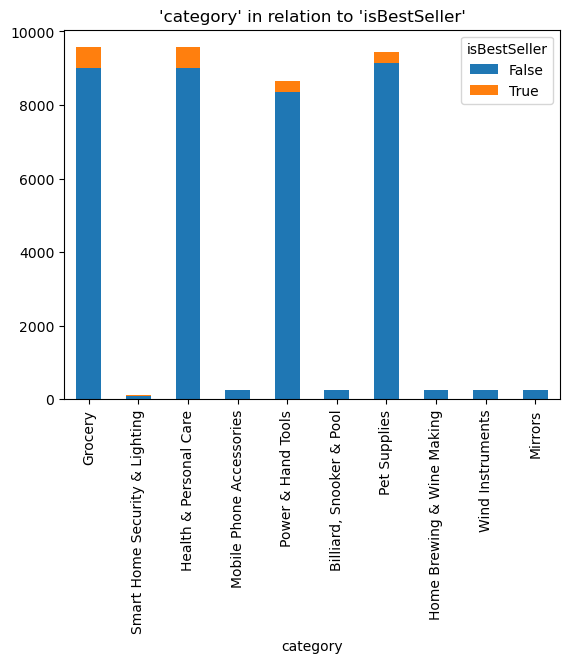

In [49]:
categories_list = [crosstab_df_percent_sorted.index[x] for x in range(10)]
print(categories_list)

crosstab_df_value_top = crosstab_df_value.loc[categories_list]
#crosstab_df_value_top = crosstab_df_percent_sorted.loc[categories_list]
display(crosstab_df_value_top)
crosstab_df_value_top.plot(kind='bar', stacked=True, title= "'category' in relation to 'isBestSeller'")
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

**Conclusion Part 2:**
- 1. The product category "Desktop PCs" tends to have the highest median price (74.0)
- 2. The product category "Motherboards" commands the highest average price (68.77)
- 3. The product category "Computer Memory" tends to receive the highest median rating from customers (4.7)

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [94]:
def outlier_detection(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return lower_bound, upper_bound, outliers

#df_product_prices = df["price"]
#print(df_product_prices.describe())

a, b, c = outlier_detection(df["price"])
#c = c.sort_values(ascending=True)
print(f"\nlower bound: {a}")
print(f"upper bound: {b}")


df_without_outliers = df[(df["price"] < b) & (df["price"] > a)].copy()
print(f"\nnumber of rows in df: {len(df)}")
print(f"\nnumber of outliers: {len(c)}")
print(f"\nnumber without ouliers: {len(df_without_outliers)}")

print(f"df-outliers: {len(df)-len(c)} vs df without outliers: {len(df_without_outliers)}")


lower bound: -44.01
upper bound: 99.99000000000001

number of rows in df: 2443651

number of outliers: 327688

number without ouliers: 2115963
df-outliers: 2115963 vs df without outliers: 2115963


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Desktop PCs,169.0,66.915562,28.167505,3.99,55.4100,74.00,89.9500,99.99
Boxing Shoes,3873.0,67.417803,18.752522,0.89,63.4600,69.79,77.0200,99.99
Tablets,4638.0,66.552971,25.390369,1.90,57.7900,69.00,87.2075,99.99
Graphics Cards,57.0,65.103509,22.594322,9.99,46.5400,68.54,79.9900,99.99
Motherboards,74.0,68.772432,20.632565,8.99,58.6550,67.92,85.7400,99.99
...,...,...,...,...,...,...,...,...
Adapters,254.0,8.750197,6.257183,1.99,5.3925,7.05,9.9900,67.18
Make-up,18718.0,10.612918,9.528028,0.01,4.9900,7.00,12.7850,99.99
Signs & Plaques,5279.0,8.210513,5.586570,1.59,4.4900,6.99,9.9900,99.00


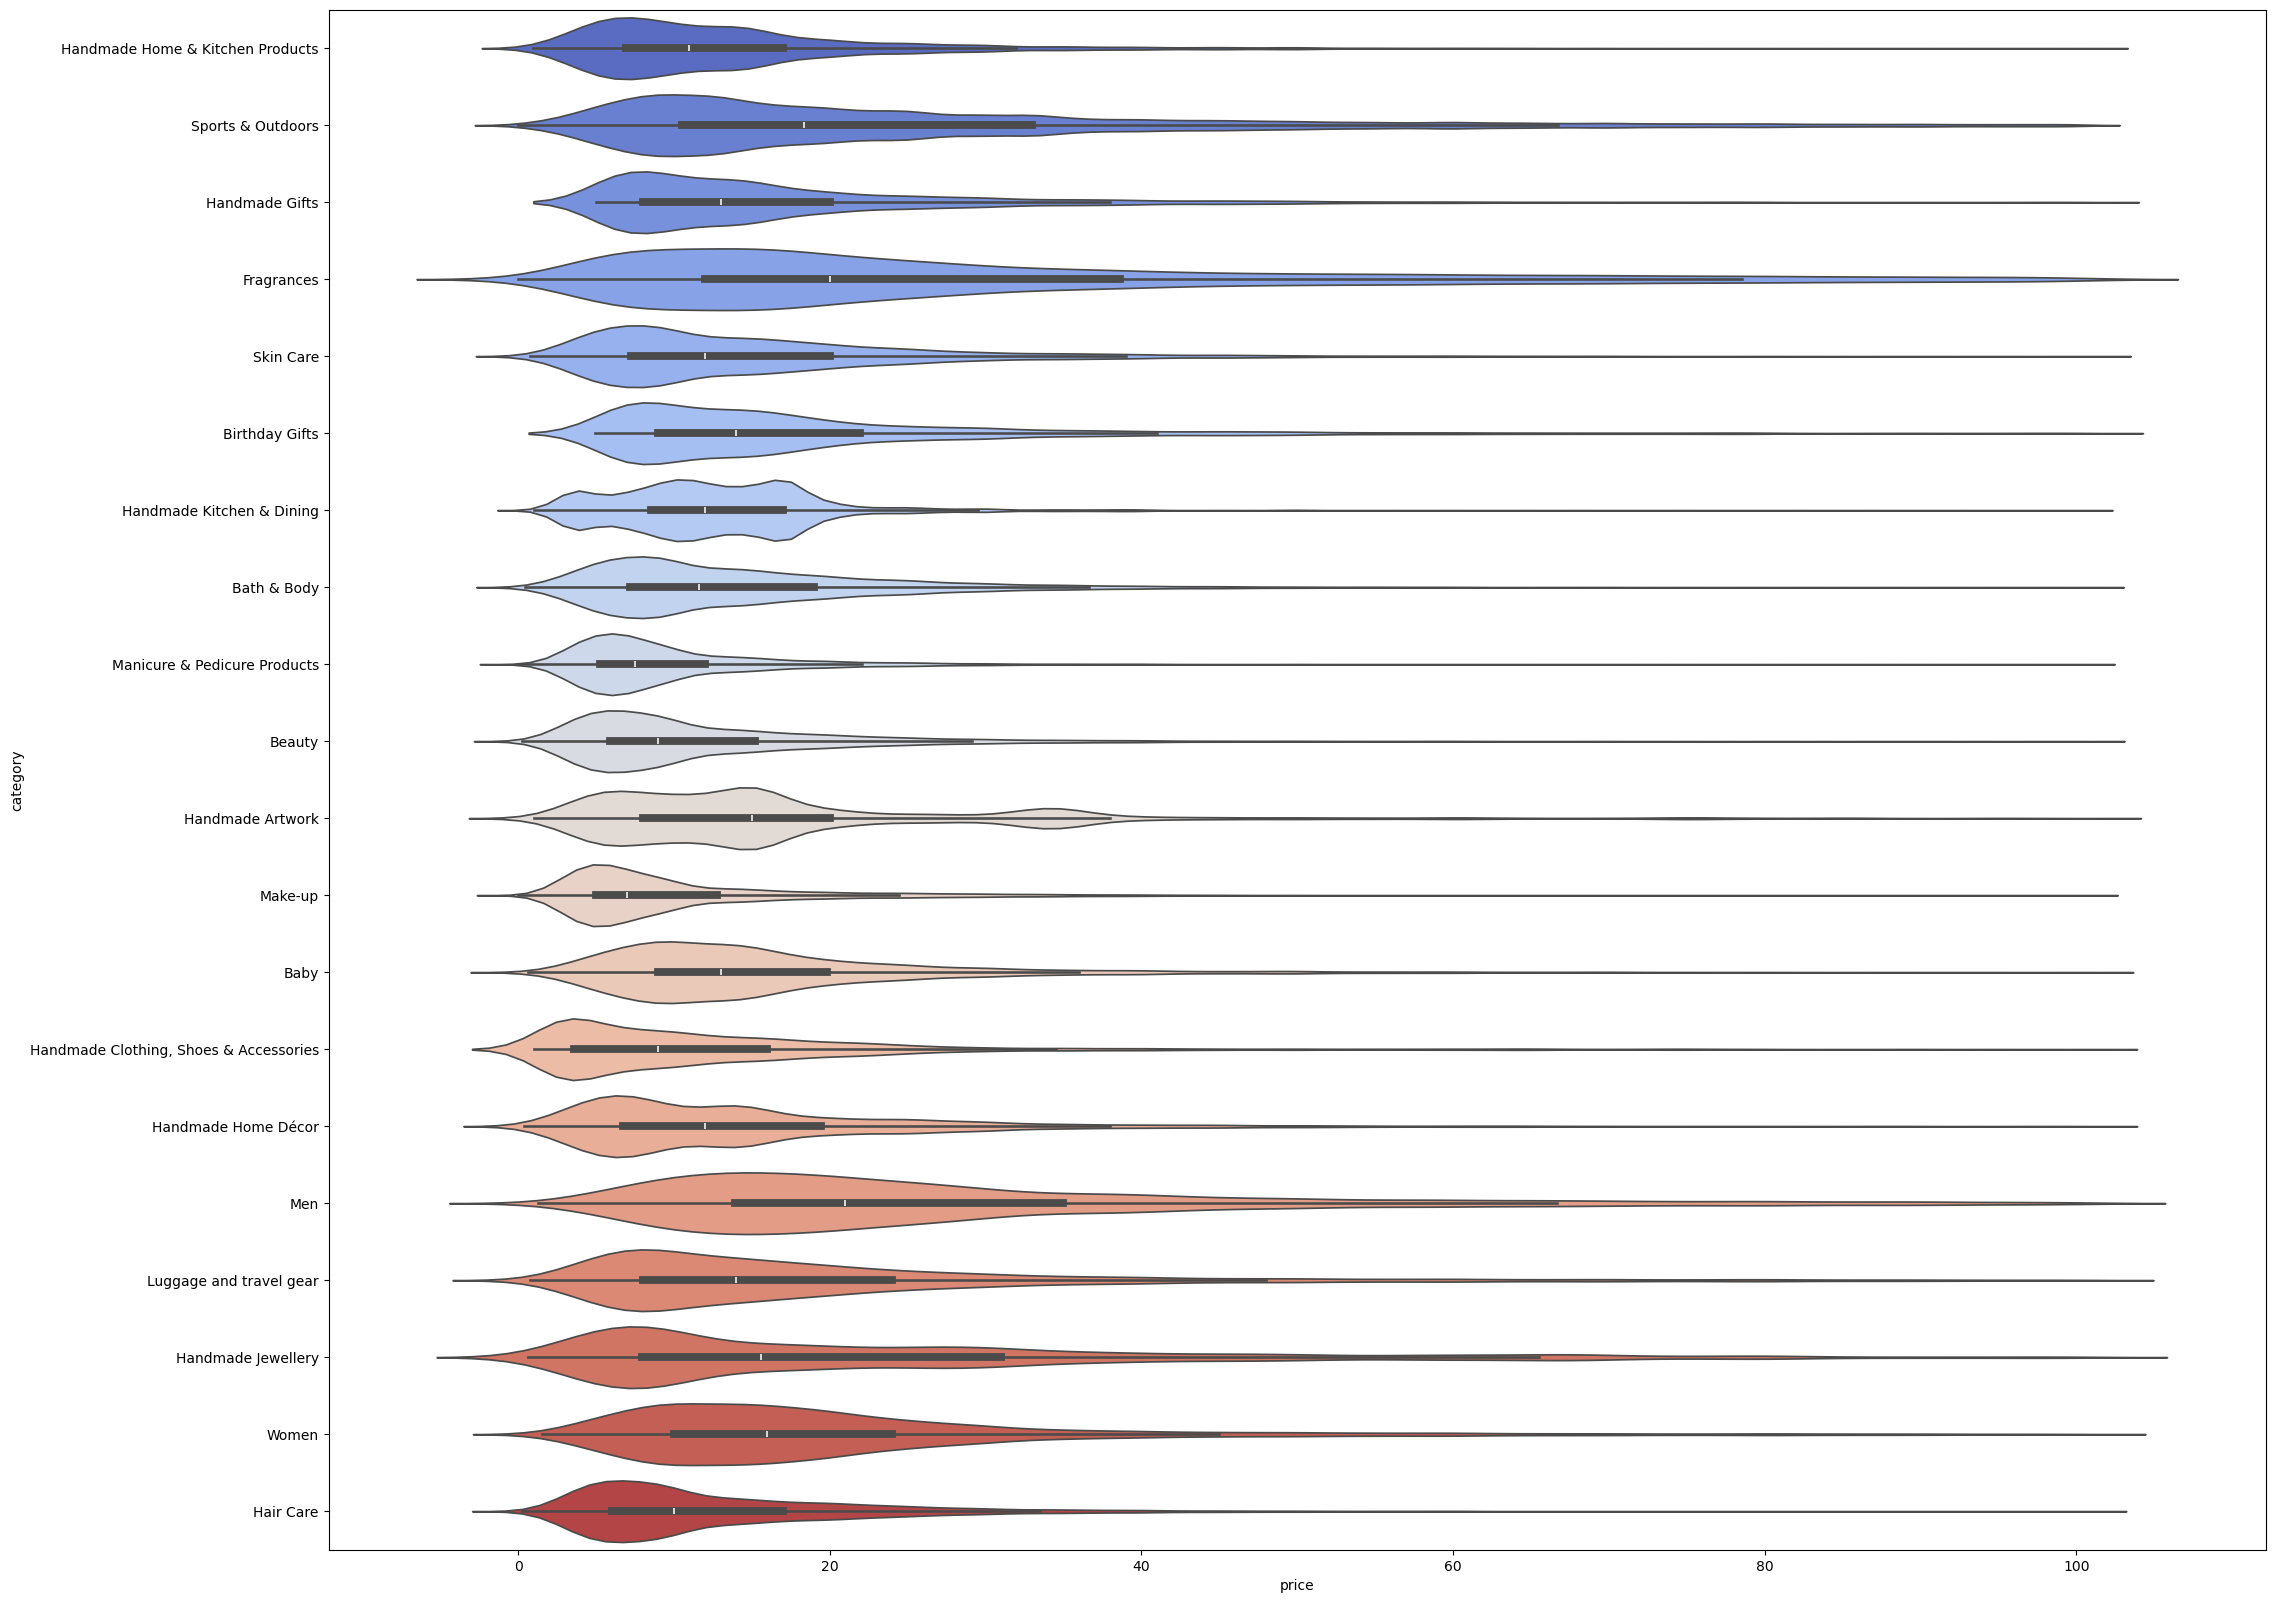

In [ ]:
top_20_cat = df_without_outliers.groupby("category").size().sort_values(ascending=False)[:20].index.to_list()       # take the top 20 categories based on frequency and put them in a list

df_without_outliers_top_20_cat = df_without_outliers[df_without_outliers["category"].isin(top_20_cat)]              # separate all rows that are one of these top 20 categories
                                                                                                                    # if the category value of a row is in list "top_20_cat"

display(df_without_outliers.groupby("category").describe()["price"].sort_values(by="50%", ascending=False))         # display the description of the column "price" for all categories and sort by the median

plt.figure(figsize=(25, 20))
sns.violinplot(data=df_without_outliers_top_20_cat, y="category", x="price", palette="coolwarm", hue="category")    # plot violin plot of the top 20 categories based on frequency
plt.show()

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Motherboards,74.0,68.772432,20.632565,8.99,58.6550,67.92,85.7400,99.99
Boxing Shoes,3873.0,67.417803,18.752522,0.89,63.4600,69.79,77.0200,99.99
Desktop PCs,169.0,66.915562,28.167505,3.99,55.4100,74.00,89.9500,99.99
Tablets,4638.0,66.552971,25.390369,1.90,57.7900,69.00,87.2075,99.99
Graphics Cards,57.0,65.103509,22.594322,9.99,46.5400,68.54,79.9900,99.99
...,...,...,...,...,...,...,...,...
Bedding Accessories,205.0,8.835220,6.074399,2.42,5.4900,7.09,9.4900,44.99
Adapters,254.0,8.750197,6.257183,1.99,5.3925,7.05,9.9900,67.18
Signs & Plaques,5279.0,8.210513,5.586570,1.59,4.4900,6.99,9.9900,99.00


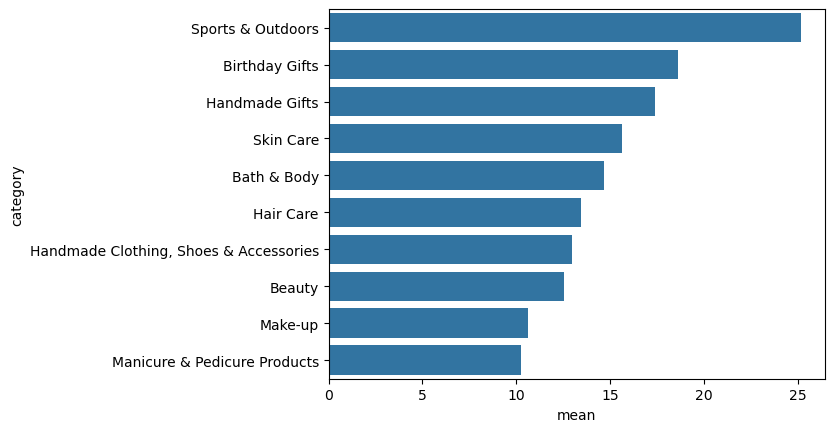

In [ ]:
top_10_cat = df_without_outliers.groupby("category").size().sort_values(ascending=False)[:10].index.to_list()   # take the top 10 categories based on frequency and put them in a list

df_without_outliers_top_10_cat = df_without_outliers[df_without_outliers["category"].isin(top_10_cat)]          # separate all rows that are one of these top 10 categories
                                                                                                                # if the category value of a row is in list "top_10_cat"                                                                                                      

df_without_outliers_top_10_cat_mean = df_without_outliers_top_10_cat.groupby("category").describe()["price"].sort_values(by="mean", ascending=False)    # calculating mean and sort values by mean

display(df_without_outliers.groupby("category").describe()["price"].sort_values(by="mean", ascending=False))    # display the description of the column "price" for all categories and sort by the mean

sns.barplot(x="mean", y="category", data=df_without_outliers_top_10_cat_mean, errorbar=None)                    # plot bar chart of the mean values for top 10 categories based on frequency
plt.show()


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Computer Memory,211.0,4.299526,1.211748,0.0,4.5,4.7,4.7,5.0
Building & Construction Toys,8685.0,3.988440,1.493782,0.0,4.2,4.6,4.7,5.0
Office Paper Products,9090.0,4.430000,0.872881,0.0,4.5,4.6,4.7,5.0
Luxury Food & Drink,657.0,4.544140,0.278771,3.8,4.4,4.6,4.7,5.0
Kids' Play Figures,9377.0,4.172838,1.223872,0.0,4.3,4.6,4.7,5.0
...,...,...,...,...,...,...,...,...
Hockey Shoes,221.0,1.506335,2.160020,0.0,0.0,0.0,4.3,5.0
Hi-Fi Receivers & Separates,7841.0,0.617460,1.482220,0.0,0.0,0.0,0.0,5.0
Handmade Kitchen & Dining,17346.0,0.728110,1.698643,0.0,0.0,0.0,0.0,5.0


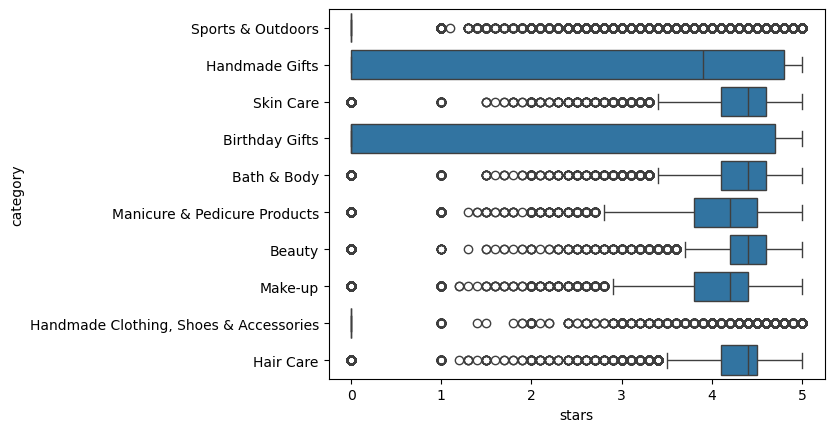

In [190]:
top_10_cat = df_without_outliers.groupby("category").size().sort_values(ascending=False)[:10].index.to_list()   # take the top 10 categories based on frequency and put them in a list

df_without_outliers_top_10_cat = df_without_outliers[df_without_outliers["category"].isin(top_10_cat)]          # separate all rows that are one of these top 10 categories
                                                                                                                # if the category value of a row is in list "top_10_cat"                                                                                                      

df_without_outliers_top_10_cat_median = df_without_outliers_top_10_cat.groupby("category").describe()["stars"].sort_values(by="50%", ascending=False)    # calculating median and sort values by median

display(df_without_outliers.groupby("category").describe()["stars"].sort_values(by="50%", ascending=False))     # display the description of the column "stars" for all categories and sort by the median


sns.boxplot(x="stars", y="category", data=df_without_outliers_top_10_cat)                                       # plot box plot of the ratings for top 10 categories based on frequency
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

**Conclusion Part 3:**
- 1. ss
- 2. ss

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?